# Classificação de Câncer de Mama com Árvores de Decisão e validação N-Fold

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn, Matplotlib  
- **Arquivo Original:** `N_Fold_CrossValidation_protocol_DecisionTree_Breast_Cancer.ipynb`  

---


In [1]:
# Importing the necessary classes/methods
from sklearn import tree
from sklearn.datasets import load_digits, load_breast_cancer
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score


In [2]:
# Loading the dataset
X,y=load_breast_cancer(return_X_y=True)
print(X.shape)
print(y.shape)

(569, 30)
(569,)


In [3]:
# Model declaration
clf=tree.DecisionTreeClassifier(criterion='entropy', max_depth=10, random_state=46)

# Model training and evaluation
N_folds=10
result=cross_val_score(clf, X,y, cv=N_folds)
print('Taxa de acerto (acurácia), média:', result.mean() * 100)
print('Taxa de acerto (acurácia), std:', result.std() * 100)

# Test prediction
ypred=cross_val_predict(clf, X,y, cv=N_folds)

# Ploting the confusion matrix
cm=confusion_matrix(y, ypred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['M', 'B'])
disp.plot()

# Precision
print('Precision score:', precision_score(y, ypred, average='weighted'))
# Recall
print('Recall score:', recall_score(y, ypred, average='weighted'))
# F1 score
print('F1 score:', f1_score(y, ypred, average='weighted'))


Taxa de acerto (acurácia), média: 93.1453634085213
Taxa de acerto (acurácia), std: 3.183080730939764
Precision score: 0.9317055903039237
Recall score: 0.9314586994727593
F1 score: 0.9315548749752331
Error in callback <function flush_figures at 0x7f16c64b8160> (for post_execute):


KeyboardInterrupt: 

Relevância dos atributos (calculado pela árvore): [0.         0.01094813 0.         0.01347288 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.02957055 0.         0.         0.         0.
 0.         0.00888793 0.         0.05690144 0.69254819 0.01251271
 0.06838838 0.         0.         0.07702027 0.02466714 0.00508236]


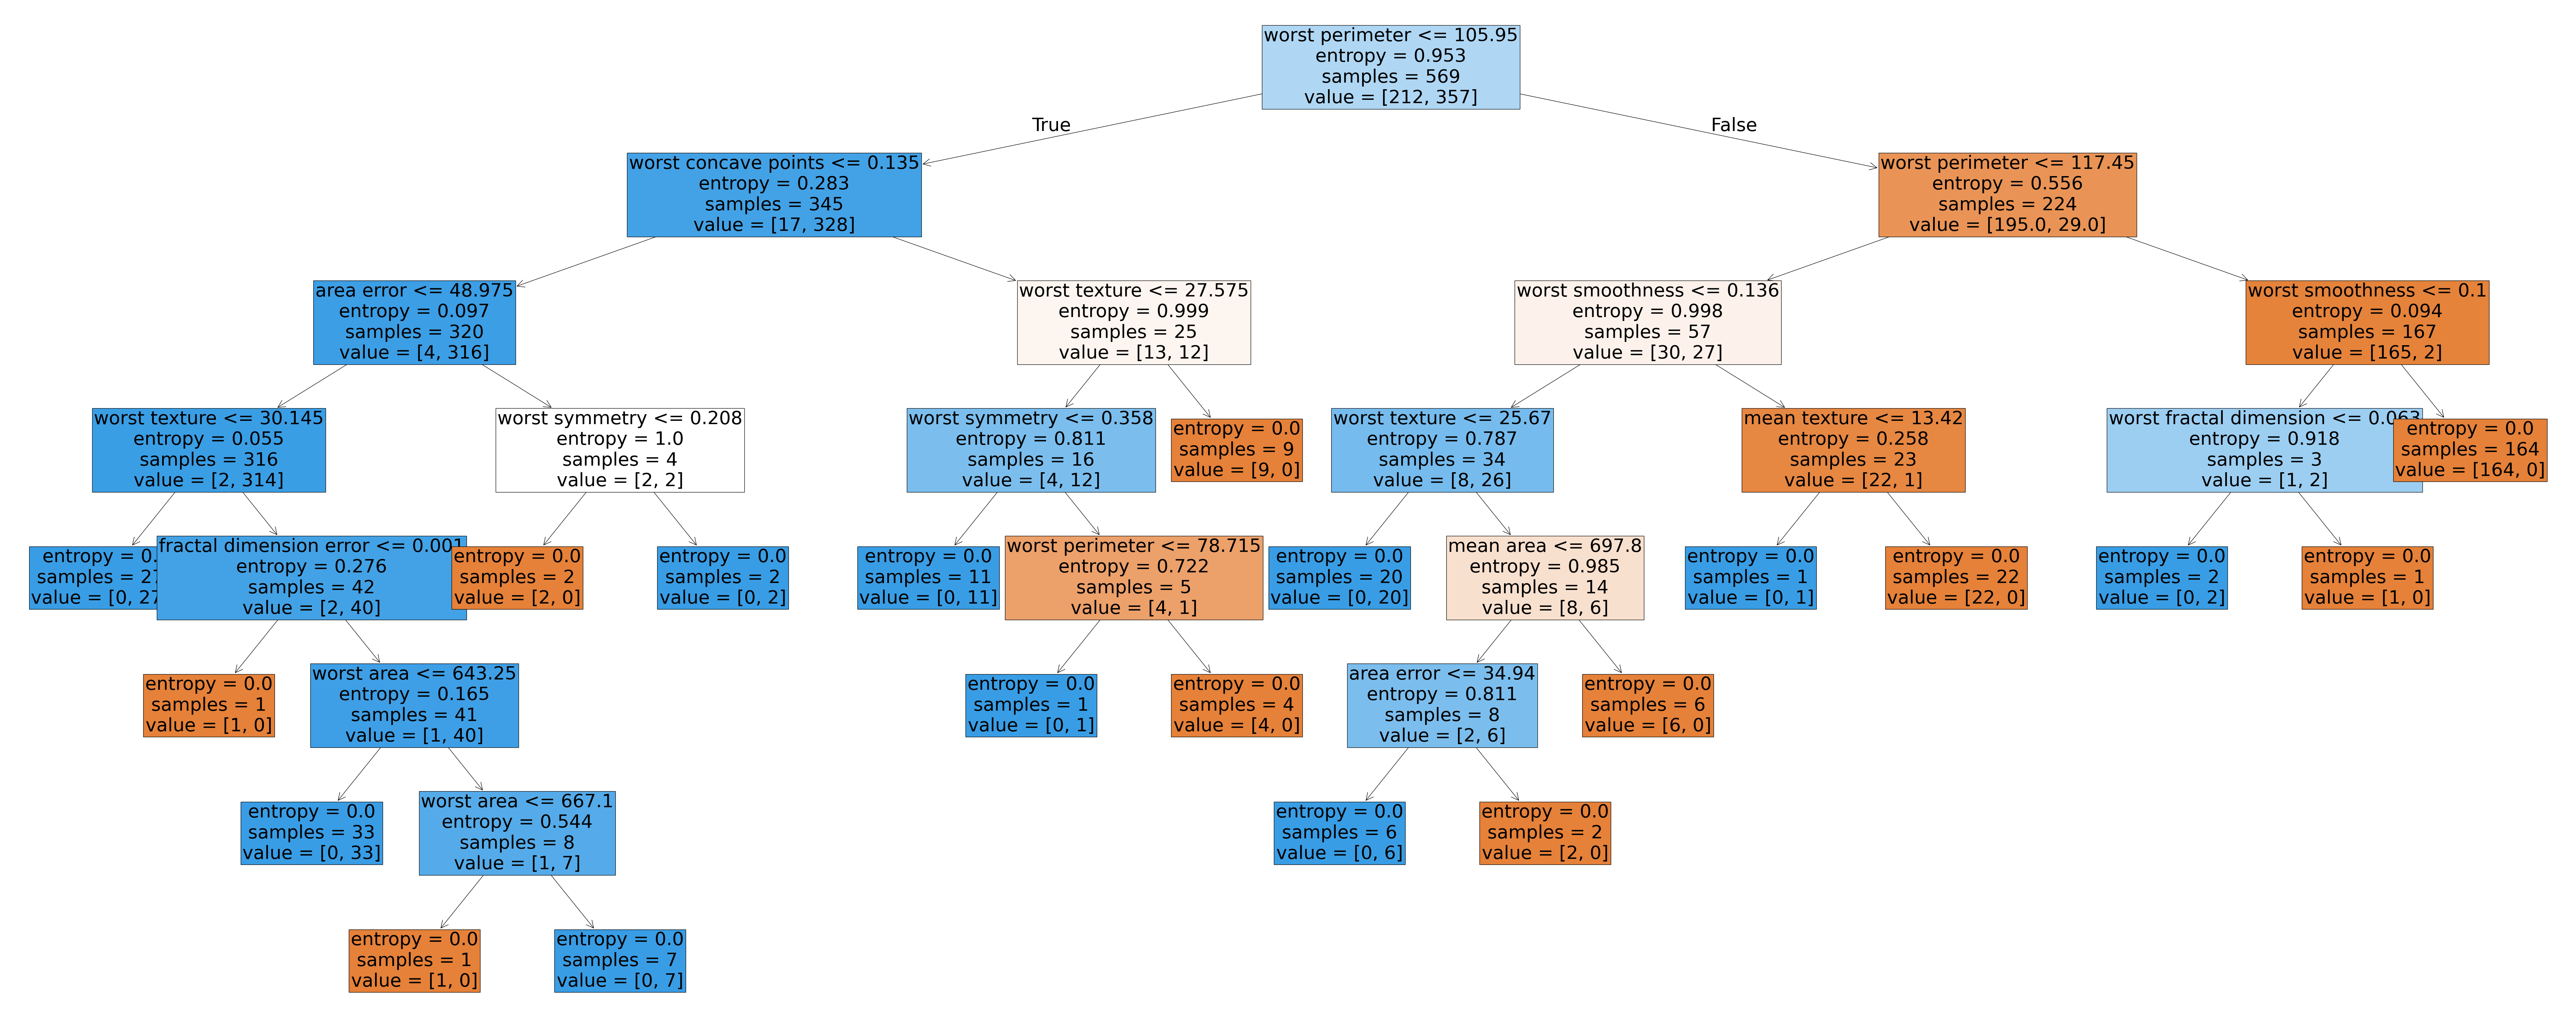

In [4]:
# plotando a árvore após treinamento com a base toda (EXECUTE SOMENTE PARA ÁRVORE)
from sklearn import tree

# carregando a base com todos os detalhes
base=load_breast_cancer()
X=base.data
y=base.target
att=base.feature_names

clf=tree.DecisionTreeClassifier(criterion='entropy')
clf.fit(X,y)

import matplotlib.pyplot as plt
import numpy as np
from sklearn import tree

_, ax = plt.subplots(figsize=(100,40))
x=tree.plot_tree(clf, feature_names=att, filled=True, ax=ax, fontsize=40)

print("Relevância dos atributos (calculado pela árvore):", clf.feature_importances_)